<a href="https://colab.research.google.com/github/saitejasrireddyveldi-collab/ML_Lab-2026-27/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Student Performance Prediction Using Machine Learning**

**Aim:** To predict whether a student will Pass or Fail based on study hours, attendance, previous marks and assignment scores using machine learning algorithms.

Student Performance Prediction is a machine learning project that analyzes students' academic information and predicts their performance.

It helps teachers identify students who may need additional support and improve their academic results.

 The system analyzes study hours, attendance, previous marks, assignment marks and classroom participation. It uses machine learning algorithms to predict whether a student is likely to Pass or Fail.

## **Step 1: Import libraries**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, classification_report

## **Step 2: Create the dataset**

In [4]:
np.random.seed(42)

n = 200

data = pd.DataFrame({
    'Study_Hours': np.random.randint(1, 10, n),
    'Attendance': np.random.randint(30, 101, n),
    'Previous_Marks': np.random.randint(20, 101, n),
    'Assignment_Marks': np.random.randint(20, 101, n),
    'Participation': np.random.randint(1, 11, n)
})

# Generate sample performance labels
score = (
    data['Study_Hours'] * 3 +
    data['Attendance'] * 0.3 +
    data['Previous_Marks'] * 0.3 +
    data['Assignment_Marks'] * 0.2 +
    data['Participation'] * 2
)

data['Performance'] = np.where(
    score >= 65, 'Pass', 'Fail'
)

data.to_csv('student_performance.csv', index=False)

print(data.head())
print("\nDataset shape:", data.shape)
print("\nMissing values:\n", data.isnull().sum())

   Study_Hours  Attendance  Previous_Marks  Assignment_Marks  Participation  \
0            7          30              51                84              4   
1            4          40              43                37              6   
2            8          86              31                68              6   
3            5          79              69                30              1   
4            7          52              54                45              8   

  Performance  
0        Pass  
1        Fail  
2        Pass  
3        Pass  
4        Pass  

Dataset shape: (200, 6)

Missing values:
 Study_Hours         0
Attendance          0
Previous_Marks      0
Assignment_Marks    0
Participation       0
Performance         0
dtype: int64


## **Step 3: Separate input and output**

In [5]:
X = data.drop('Performance', axis=1)

y = data['Performance']

print("Input data:")
print(X.head())

print("\nOutput data:")
print(y.head())

Input data:
   Study_Hours  Attendance  Previous_Marks  Assignment_Marks  Participation
0            7          30              51                84              4
1            4          40              43                37              6
2            8          86              31                68              6
3            5          79              69                30              1
4            7          52              54                45              8

Output data:
0    Pass
1    Fail
2    Pass
3    Pass
4    Pass
Name: Performance, dtype: object


## **Step 4: Split training and testing data**

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (160, 5)
Testing data: (40, 5)


## **Step 5: Apply machine learning algorithms**

In [7]:
models = {
    'KNN': make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'Logistic Regression': make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    'Random Forest': RandomForestClassifier(
        random_state=42
    ),

    'SVM': make_pipeline(
        StandardScaler(),
        SVC()
    )
}

results = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)

    results[name] = accuracy

    print(name, "Accuracy:",
          round(accuracy * 100, 2), "%")

KNN Accuracy: 92.5 %
Decision Tree Accuracy: 80.0 %
Logistic Regression Accuracy: 100.0 %
Random Forest Accuracy: 92.5 %
SVM Accuracy: 92.5 %


## **Step 6: Compare model accuracy**

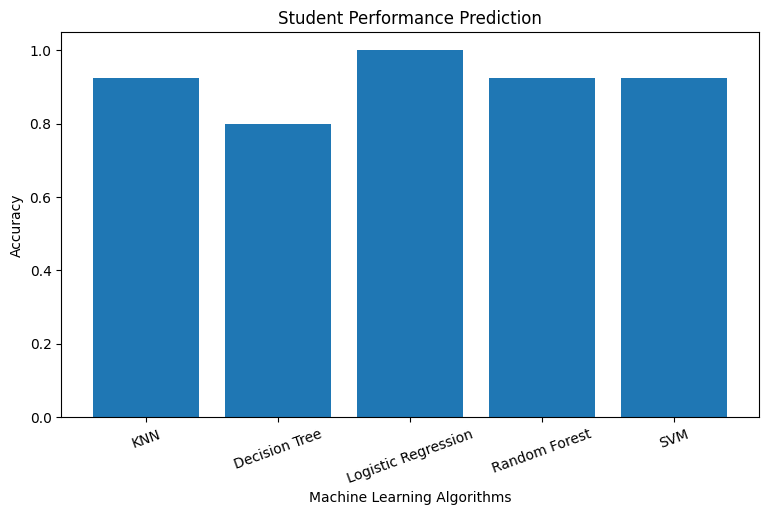

In [8]:
plt.figure(figsize=(9, 5))

plt.bar(
    results.keys(),
    results.values()
)

plt.xlabel("Machine Learning Algorithms")
plt.ylabel("Accuracy")
plt.title("Student Performance Prediction")

plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.show()

## **Step 7: Classification report**

In [9]:
best_name = max(results, key=results.get)

best_model = models[best_name]

y_pred = best_model.predict(X_test)

print("Best Algorithm:", best_name)

print("\nClassification Report:")

print(classification_report(y_test, y_pred))

Best Algorithm: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00        10
        Pass       1.00      1.00      1.00        30

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



### **Step 8: Predict a new student's performance**

In [10]:
new_student = pd.DataFrame([{
    'Study_Hours': 6,
    'Attendance': 85,
    'Previous_Marks': 75,
    'Assignment_Marks': 80,
    'Participation': 8
}])

prediction = best_model.predict(new_student)

print("Predicted Student Performance:", prediction[0])

Predicted Student Performance: Pass


## **Conclusion:**

The Student Performance Prediction System uses machine learning to analyze student academic information and predict their performance. Different algorithms are compared to identify a suitable model. This system can help teachers understand student performance and provide additional academic support.